# Задача 5: Лінійна регресія в Python

У цьому завданні ми працюватимемо з інструментами та методами візуалізації даних, а також обчисленням деяких простих характеристичних мір за допомогою бібліотек pandas, statsmodels та scikit-learn. Наша мета — застосувати всі базові техніки та зробити правильні висновки. Ми використовуємо набір даних Ames Housing, який доступний для завантаження на Kaggle: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/overview або може бути завантажений напряму через репозиторії даних.

**Застереження щодо завантаження даних:** У датасеті Ames Housing абревіатура NA у категоріальних колонках позначає фізичну відсутність ознаки (наприклад, «немає гаража» чи «немає підвалу»), а не пропущене значення. Щоб pandas за замовчуванням не перетворював такі категорії на NaN, під час завантаження через pd.read_csv() використовуйте параметр keep_default_na=False або явно налаштуйте аргумент na_values (наприклад, na_values=['']).

Повний набір даних містить майже 3000 спостережень та 81 ознаку. Загальна мета полягає в тому, щоб пояснити ціни продажу SalePrice.

***Answer***

[Умова](../input/assignment_3.pdf). Дані — повна версія Ames Housing ([De Cock, 2011](https://jse.amstat.org/v19n3/decock/AmesHousing.txt)), опис змінних — [DataDocumentation.txt](../input/DataDocumentation.txt). Файл має 2930 продажів і 82 колонки: ідентифікатори `Order`, `PID`, 79 ознак і `SalePrice`. Назви колонок зведено до вигляду з умови (`Lot Area` → `LotArea`). Ціни — у доларах США, площі — у кв. футах.

**Повна модель** — регресія `SalePrice` на всі пояснювальні змінні набору. Так випливає з умови: у пункті 7 «більшість змінних можуть виявитися незначущими», а в пункті 9 структурні `NA` мали бути окремими рівнями факторів. Не включаємо лише:
- `Order`, `PID` — ідентифікатори;
- `GarageYrBlt` — для 157 будинків без гаража такого року не існує; це не пропуск, і викидати всі будинки без гаража не варто;
- `TotalBsmtSF` і `GrLivArea` — точні суми інших площ (пункт 4).

Залишається 32 числові та 44 категоріальні змінні. `MSSubClass` і текстові колонки кодуємо фіктивними змінними. Оцінки `OverallQual`, `OverallCond` (1–10) для простоти залишаємо числами.

Справжні пропуски (порожні клітинки) є в `LotFrontage` (490), `MasVnrArea` (23) та кількох колонках підвалу, гаража й `Electrical`. Для регресій у пунктах 4–8, 10–11 беремо **повні спостереження: 2414 із 2930**, щоб усі моделі оцінювалися на тих самих рядках. Пункт 3 використовує всі 2930 продажів (у `LotArea` пропусків немає), пункт 9 — копію всього `df`.

Рівень значущості 0.05, `SEED = 42`. Коефіцієнти описують статистичні зв'язки, а не доведені причинні ефекти.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (дозволяє IterativeImputer)
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, KFold, cross_val_predict
from IPython.display import display

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task3").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task3"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
INPUT_DIR = TASK_DIR / "input"
FIGURES_DIR = TASK_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

SEED = 42
ALPHA = 0.05
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})
pd.set_option("display.float_format", "{:.6g}".format)
pd.set_option("display.max_columns", 30)


In [2]:
DATA_PATH = INPUT_DIR / "AmesHousing.txt"
df = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])
# Назви як у Kaggle та в умові: "Lot Area" -> "LotArea", "Year Remod/Add" -> "YearRemodAdd".
df.columns = df.columns.str.replace(" ", "").str.replace("/", "")
text_columns = list(df.select_dtypes(exclude="number").columns)
for column in text_columns:
    df[column] = df[column].str.strip()  # у SaleType є зайві пробіли, напр. "WD "

# MSSubClass і текстові колонки - категорії; рядок "NA" в них - окремий рівень.
categorical = ["MSSubClass"] + text_columns
# Order, PID - ідентифікатори; GarageYrBlt не існує для будинків без гаража;
# TotalBsmtSF і GrLivArea - точні суми інших площ (див. пункт 4).
excluded = ["Order", "PID", "SalePrice", "GarageYrBlt", "TotalBsmtSF", "GrLivArea"]
numeric = [column for column in df.columns if column not in categorical + excluded]
analysis = df.dropna(subset=numeric + categorical).copy()

print("Розмір df:", df.shape)
print(f"Числових регресорів: {len(numeric)}, категоріальних: {len(categorical)}")
missing = df.isna().sum()
display(missing[missing > 0].to_frame("Справжні пропуски (NaN)"))
display(pd.Series({column: (df[column] == "NA").sum() for column in ["Alley", "BsmtQual", "GarageType", "PoolQC", "Fence"]})
        .to_frame('Структурний рівень "NA"'))
print("Повних спостережень для регресій:", len(analysis), "з", len(df))


Розмір df: (2930, 82)
Числових регресорів: 32, категоріальних: 44


,Справжні пропуски (NaN)
LotFrontage,490
MasVnrType,23
MasVnrArea,23
BsmtQual,1
BsmtCond,1
BsmtExposure,4
BsmtFinType1,1
BsmtFinSF1,1
BsmtFinType2,2
BsmtFinSF2,1


,"Структурний рівень ""NA"""
Alley,2732
BsmtQual,79
GarageType,157
PoolQC,2917
Fence,2358


Повних спостережень для регресій: 2414 з 2930


## (1)

Перед підгонкою моделі до даних спочатку детальніше розглянемо визначення змінних та вирішимо, чи потребують деякі з них окремої обробки. Розглянемо, наприклад, першу змінну MSSubClass. Вона набуває текстових (категоріальних) значень і очевидно не може бути включена в лінійну модель у вихідному вигляді. Існує два підходи до обробки такої змінної. Один підхід полягає в присвоєнні чисел від 1 до 16 кожному можливому результату (Label Encoding). Інший підхід полягає у створенні нових фіктивних змінних (One-Hot Encoding / Dummy variables), які дорівнюють одиниці для конкретного результату і нулю в іншому випадку. Обговоріть ці два підходи та запропонуйте, який із них є більш доречним у цьому випадку. Мотивуйте своє рішення, беручи до уваги номінальну, порядкову та кардинальну шкали зі статистики. Запустіть просту регресію SalePrice на MSSubClass у тому вигляді, в якому вона є (без кодування). Перевірте, як statsmodels або scikit-learn обробляє такий тип змінної, якщо вона передана як звичайний числовий тип (int64), та як її примусово змінити на категоріальну за допомогою pd.Categorical або формул statsmodels.formula.api.ols (C(MSSubClass)).

Тип MSSubClass у DataFrame: int64


,Параметрів,R²,Скоригований R²
int64: один нахил,2,0.00724058,0.00690152
C(MSSubClass),16,0.247767,0.243895
pd.Categorical,16,0.247767,0.243895


int64-модель: {'Intercept': 189945.2, 'MSSubClass': -159.43}
Перші коефіцієнти C(MSSubClass): {'Intercept': 187356.0, 'C(MSSubClass)[T.30]': -90629.0, 'C(MSSubClass)[T.40]': -42439.0, 'C(MSSubClass)[T.45]': -75572.0}


MSSubClass,20,30,40,45,50,60,70,75,80,85,90,120,150,160,180,190
count,1079,139,6,18,287,575,128,23,118,48,109,192,1,129,17,61
mean,187356,96726.9,144917,111783,137433,239364,156526,199978,168009,149842,139809,208019,148400,137080,107671,125870


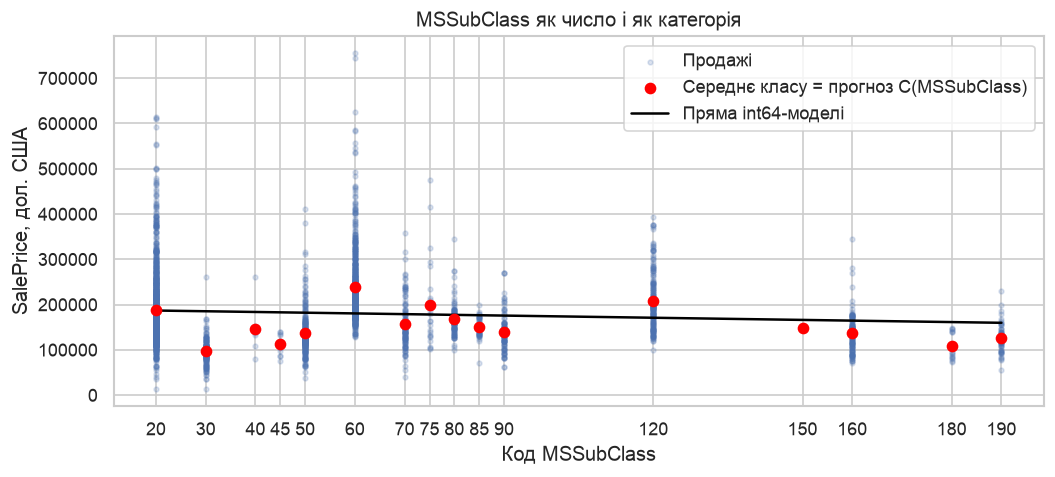

In [3]:
# Перевірте тип MSSubClass; підготуйте числову та категоріальну специфікації.
# ========= YOUR CODE STARTS HERE ========= #

print("Тип MSSubClass у DataFrame:", df["MSSubClass"].dtype)
numeric_class = smf.ols("SalePrice ~ MSSubClass", data=df).fit()          # як int64
formula_class = smf.ols("SalePrice ~ C(MSSubClass)", data=df).fit()       # C(...) у формулі
df_category = df.assign(MSSubClass=pd.Categorical(df["MSSubClass"]))
category_class = smf.ols("SalePrice ~ MSSubClass", data=df_category).fit()  # pd.Categorical
assert np.allclose(formula_class.fittedvalues, category_class.fittedvalues)

display(pd.DataFrame({
    "Параметрів": [len(m.params) for m in (numeric_class, formula_class, category_class)],
    "R²": [m.rsquared for m in (numeric_class, formula_class, category_class)],
    "Скоригований R²": [m.rsquared_adj for m in (numeric_class, formula_class, category_class)],
}, index=["int64: один нахил", "C(MSSubClass)", "pd.Categorical"]))
print("int64-модель:", numeric_class.params.round(2).to_dict())
print("Перші коефіцієнти C(MSSubClass):", formula_class.params.head(4).round(0).to_dict())

# Прогноз категоріальної моделі = середня ціна класу.
class_means = df.groupby("MSSubClass")["SalePrice"].agg(["count", "mean"])
assert np.allclose(formula_class.fittedvalues, df["MSSubClass"].map(class_means["mean"]))
display(class_means.T)

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(df["MSSubClass"], df["SalePrice"], s=8, alpha=0.2, label="Продажі")
ax.scatter(class_means.index, class_means["mean"], color="red", zorder=3, label="Середнє класу = прогноз C(MSSubClass)")
codes = np.sort(df["MSSubClass"].unique())
ax.plot(codes, numeric_class.params["Intercept"] + numeric_class.params["MSSubClass"] * codes,
        color="black", label="Пряма int64-моделі")
ax.set(xticks=codes, xlabel="Код MSSubClass", ylabel="SalePrice, дол. США",
       title="MSSubClass як число і як категорія")
ax.legend()
fig.savefig(FIGURES_DIR / "problem5_mssubclass.png")
plt.show()


***Answer***

`MSSubClass` записано числами (`int64`), але це **коди типів житла**: 20 — одноповерховий будинок 1946 р. і новіший, 30 — одноповерховий 1945 р. і старший, 60 — двоповерховий, 90 — дуплекс тощо. Це **номінальна шкала**:
- немає природного порядку (на відміну від порядкової шкали, наприклад оцінки якості 1–10);
- різниця кодів не має змісту (на відміну від кардинальної, кількісної шкали, наприклад площі): $60-20=40$ нічого не означає.

**Label Encoding** (номери 1–16 або самі коди) змусив би модель вважати, що кожен крок коду змінює ціну на ту саму суму. **One-Hot / фіктивні змінні** дають кожному класу власний зсув відносно базового класу. Тому тут доречні фіктивні змінні. Для 16 класів беремо 15 індикаторів і константу: усі 16 разом із константою дали б точну лінійну залежність (пастка фіктивних змінних).

Що робить statsmodels:
- як `int64` змінна вважається звичайним числом — оцінюється **один нахил**: $-159.43$ дол. на одиницю коду, $R^2=0.0072$;
- `C(MSSubClass)` у формулі або `pd.Categorical` перетворюють змінну на 15 фіктивних (база — клас 20): 16 параметрів, $R^2=0.2478$.

Обидва категоріальні способи дають однакові прогнози — середню ціну кожного класу (червоні точки на графіку). Наприклад, коефіцієнт `C(MSSubClass)[T.30]` $=-90629$: клас 30 у середньому дешевший за клас 20 на $187356-96727\approx 90.6$ тис. дол. Чорна пряма int64-моделі майже горизонтальна й не відображає цих різниць.

## (2)

Розгляньте такі числові пояснювальні змінні: LotFrontage, LotArea, YearBuilt, BsmtFinSF1, BsmtUnfSF. Побудуйте діаграму розсіювання (scatter plot) залежності SalePrice від цих змінних за допомогою matplotlib або seaborn. Проаналізуйте кожен графік та обговоріть потенційні проблеми, трансформації або розширення моделі, які дозволять врахувати виявлені закономірності. Пам'ятайте, що ви можете або трансформувати наявні змінні (наприклад, np.log), або створювати нові для фіксації нестандартних патернів.

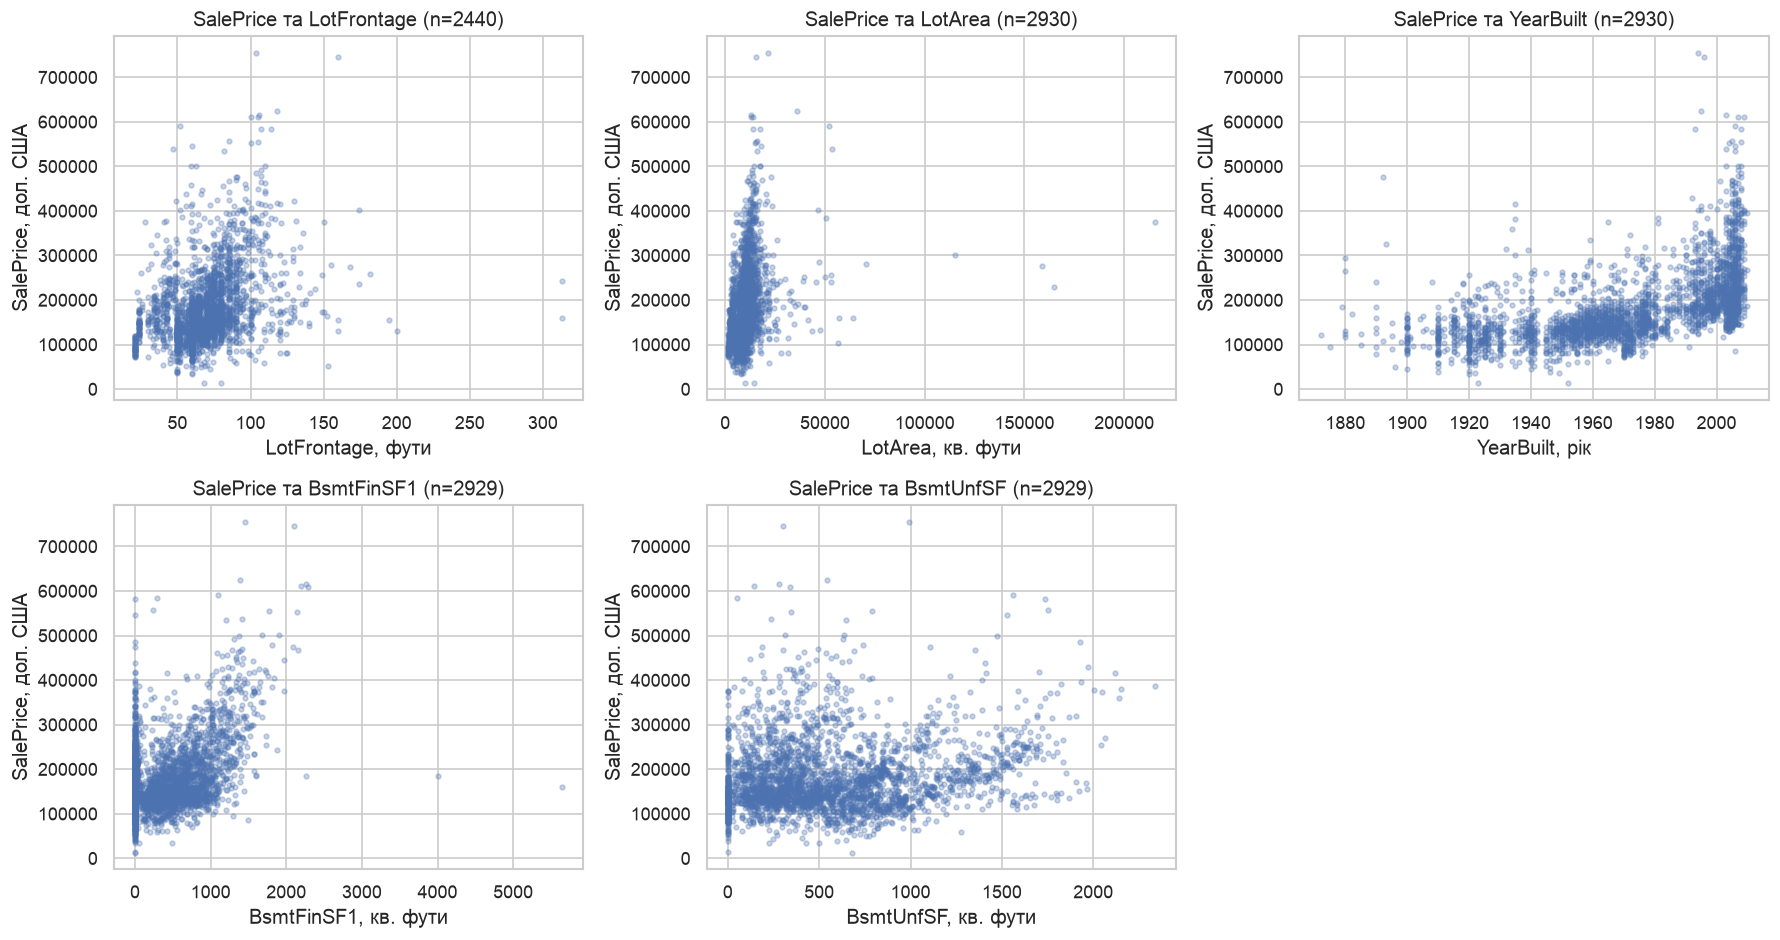

,count,min,50%,max
LotFrontage,2440,21,68,313
LotArea,2930,1300,9436.5,215245
YearBuilt,2930,1872,1973,2010
BsmtFinSF1,2929,0,370,5644
BsmtUnfSF,2929,0,466,2336


Частка нулів: {'BsmtFinSF1': 0.317, 'BsmtUnfSF': 0.083}
Кореляція з SalePrice: {'LotFrontage': 0.357, 'LotArea': 0.267, 'YearBuilt': 0.558, 'BsmtFinSF1': 0.433, 'BsmtUnfSF': 0.183, 'SalePrice': 1.0}


,Order,Значення,SalePrice,Змінна
1265,1266,313,242000,LotFrontage
1498,1499,313,160000,LotFrontage
956,957,215245,375000,LotArea
1570,1571,164660,228950,LotArea
1498,1499,5644,160000,BsmtFinSF1
2180,2181,4010,183850,BsmtFinSF1


YearBuilt,"(1870, 1920]","(1920, 1950]","(1950, 1980]","(1980, 2000]","(2000, 2010]"
count,233,437,1050,475,735
median,119000,126000,142776,200000,226000
std,48793.2,49699.8,41030.8,73249.3,88353.9


In [4]:
# Побудуйте окремі графіки для перелічених п’яти змінних.
# ========= YOUR CODE STARTS HERE ========= #

scatter_columns = ["LotFrontage", "LotArea", "YearBuilt", "BsmtFinSF1", "BsmtUnfSF"]
units = {"LotFrontage": "фути", "LotArea": "кв. фути", "YearBuilt": "рік",
         "BsmtFinSF1": "кв. фути", "BsmtUnfSF": "кв. фути"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, scatter_columns):
    pairs = df[[column, "SalePrice"]].dropna()
    ax.scatter(pairs[column], pairs["SalePrice"], s=8, alpha=0.3)
    ax.set(title=f"SalePrice та {column} (n={len(pairs)})",
           xlabel=f"{column}, {units[column]}", ylabel="SalePrice, дол. США")
axes.flat[-1].axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "problem5_scatter.png")
plt.show()

display(df[scatter_columns].describe().T[["count", "min", "50%", "max"]])
print("Частка нулів:", (df[["BsmtFinSF1", "BsmtUnfSF"]] == 0).mean().round(3).to_dict())
print("Кореляція з SalePrice:", df[scatter_columns + ["SalePrice"]].corr()["SalePrice"].round(3).to_dict())
display(pd.concat([df.nlargest(2, column)[["Order", column, "SalePrice"]].rename(columns={column: "Значення"})
                   .assign(Змінна=column) for column in ["LotFrontage", "LotArea", "BsmtFinSF1"]]))
year_groups = pd.cut(df["YearBuilt"], bins=[1870, 1920, 1950, 1980, 2000, 2010])
display(df.groupby(year_groups, observed=True)["SalePrice"].agg(["count", "median", "std"]).T)


***Answer***

- **LotFrontage** (кореляція 0.357): ціна росте приблизно до 100 футів фасаду, далі зростання слабне; є кілька дуже широких ділянок (до 313 футів). Можна спробувати `np.log(LotFrontage)` або квадратичний член. Також ця змінна має 490 пропусків (пункт 9).
- **LotArea** (0.267): більшість ділянок менші за 20 тис. кв. футів, але є кілька величезних (до 215245). Розподіл сильно скошений праворуч; такі точки матимуть великий важіль. Ціна з площею росте дедалі повільніше, тому доречний `np.log(LotArea)`.
- **YearBuilt** (0.558, найсильніший зв'язок): залежність опукла. Медіанна ціна: 119 тис. (до 1920 р.), 126 тис. (1921–1950), 143 тис. (1951–1980), 200 тис. (1981–2000), 226 тис. (після 2000). Для нових будинків більший і розкид (стандартне відхилення 73–88 тис. проти 41–50 тис.). Можна додати $YearBuilt^2$, вік будинку `YrSold - YearBuilt` або моделювати `log(SalePrice)`.
- **BsmtFinSF1** (0.433): 31.7% нулів (немає обробленої площі підвалу) — вертикальна смуга біля 0. Для додатних значень зв'язок близький до лінійного. Дві точки з площею 4010 і 5644 мають низьку ціну (Order 2181 і 1499) — потенційні викиди. Розширення: індикатор `BsmtFinSF1 > 0`.
- **BsmtUnfSF** (0.183): слабкий зв'язок і великий розкид; 8.3% нулів. Окремо ця площа мало пояснює; її краще розглядати разом з іншими площами підвалу.

Загалом розкид цін зростає для дорожчих будинків (гетероскедастичність), а сама ціна скошена праворуч — це аргументи за `np.log(SalePrice)`. Будинок Order 1499 крайній одразу за кількома змінними. У пунктах 3–8 за умовою трансформацій не застосовуємо.

## (3)

Підгоніть просту лінійну регресію за допомогою класу OLS з бібліотеки statsmodels без виконання обговорених вище трансформацій. Виберіть один із числових регресорів, наприклад, LotArea. Запишіть відповідну гіпотезу для t-тесту. Наведіть формулу для тест-статистики, поясніть компоненти цієї формули та вкажіть значення для цих компонентів із регресійного звіту (summary()). Оцініть якість підгонки (goodness-of-fit) моделі. Поясніть своїми словами різницю між $R^2$ та скоригованим (adjusted) $R^2$.

In [5]:
# Оцініть модель через sm.OLS та виведіть summary().
# ========= YOUR CODE STARTS HERE ========= #

simple_model = sm.OLS(df["SalePrice"], sm.add_constant(df[["LotArea"]])).fit()
print(simple_model.summary())

beta_1 = simple_model.params["LotArea"]
se_1 = simple_model.bse["LotArea"]
t_1 = (beta_1 - 0) / se_1
p_1 = 2 * stats.t.sf(abs(t_1), df=simple_model.df_resid)
assert np.isclose(t_1, simple_model.tvalues["LotArea"])
assert np.isclose(p_1, simple_model.pvalues["LotArea"])
display(pd.Series({"n": simple_model.nobs, "beta_1": beta_1, "SE(beta_1)": se_1, "t": t_1,
                   "df = n - 2": simple_model.df_resid, "p": p_1,
                   "t_0.975,df": stats.t.ppf(1 - ALPHA / 2, simple_model.df_resid),
                   "R²": simple_model.rsquared, "Скоригований R²": simple_model.rsquared_adj,
                   "RMSE залишків, дол.": np.sqrt(simple_model.mse_resid)}).to_frame("Значення"))


                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.071
Model:                            OLS   Adj. R-squared:                  0.071
Method:                 Least Squares   F-statistic:                     223.9
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           7.63e-49
Time:                        13:36:45   Log-Likelihood:                -37124.
No. Observations:                2930   AIC:                         7.425e+04
Df Residuals:                    2928   BIC:                         7.426e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.534e+05   2319.909     66.112      0.0

,Значення
n,2930
beta_1,2.70224
SE(beta_1),0.180575
t,14.9646
df = n - 2,2928
p,7.63384e-49
"t_0.975,df",1.96077
R²,0.0710485
Скоригований R²,0.0707312
"RMSE залишків, дол.",77009.6


***Answer***

Модель: $SalePrice_i=\beta_0+\beta_1 LotArea_i+\varepsilon_i$, $n=2930$.

Гіпотези t-тесту: $H_0:\beta_1=0$ (площа ділянки лінійно не пов'язана з ціною) проти $H_1:\beta_1\ne0$.

$$t=\frac{\widehat\beta_1-0}{SE(\widehat\beta_1)},\qquad SE(\widehat\beta_1)=\sqrt{\frac{\widehat\sigma^2}{\sum_i(x_i-\bar x)^2}},\qquad df=n-2.$$

Компоненти з `summary()`:
- $\widehat\beta_1=2.7022$ (`coef`) — оцінений нахил: +1 кв. фут ділянки відповідає в середньому +2.70 дол. ціни;
- $SE(\widehat\beta_1)=0.1806$ (`std err`) — наскільки оцінка коливалася б від вибірки до вибірки;
- 0 — значення $\beta_1$ за $H_0$;
- $t=2.7022/0.1806=14.96$ (`t`), $df=2928$ (`Df Residuals`);
- $p=7.6\cdot10^{-49}$ (`P>|t|` показує 0.000).

$|t|=14.96>t_{0.975,2928}=1.961$, тому $H_0$ відхиляємо: площа ділянки статистично значуща.

**Якість підгонки** слабка: $R^2=0.071$, тобто площа ділянки пояснює лише 7.1% варіації цін. Типова похибка (RMSE залишків) — близько 77 тис. дол. F-статистика 223.9 для однієї змінної дорівнює $t^2$. Значущий коефіцієнт ще не означає добру модель. Також `summary()` показує ненормальні залишки (Jarque–Bera = 4394). Великий `Cond. No.` тут пов'язаний лише з масштабом: значення `LotArea` — десятки тисяч кв. футів, а константа дорівнює 1. З одним регресором мультиколінеарності немає.

**$R^2$ і скоригований $R^2$:**
$$R^2=1-\frac{RSS}{TSS},\qquad \bar R^2=1-\frac{RSS/(n-k)}{TSS/(n-1)}.$$
$R^2$ — частка поясненої варіації; він ніколи не зменшується при додаванні змінної, навіть зовсім шумової. Скоригований $R^2$ штрафує за кількість параметрів $k$ і зростає лише тоді, коли нова змінна достатньо зменшує RSS. Тут $k=2$, тому різниця мізерна: 0.0710 проти 0.0707. Для повної моделі з 269 параметрами різниця вже помітна: 0.9399 проти 0.9324.

## (4)

Якщо ви хочете стверджувати, що змінна MSSubClass є незначущою, і використовуєте модель із фіктивними змінними, то вам необхідно перевірити одночасну (спільну) незначущість усіх даммі-змінних, що походять від факторної змінної MSSubClass. Запустіть тест для загальної лінійної гіпотези за допомогою методу f_test() у statsmodels та зробіть висновок про значущість MSSubClass. Запишіть матрицю та вектор, які необхідні для формулювання цієї гіпотези в межах лінійної моделі.

In [6]:
# Підготуйте модель із фіктивними змінними, матрицю обмежень і f_test().
# ========= YOUR CODE STARTS HERE ========= #

# TotalBsmtSF і GrLivArea не включаємо: це точні суми інших площ моделі.
assert (analysis["TotalBsmtSF"] == analysis[["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]].sum(axis=1)).all()
assert (analysis["GrLivArea"] == analysis[["1stFlrSF", "2ndFlrSF", "LowQualFinSF"]].sum(axis=1)).all()

# Фіктивні змінні; базова категорія кожного фактора - найчастіша.
blocks = [analysis[numeric].astype(float)]
for column in categorical:
    dummies = pd.get_dummies(analysis[column], prefix=column, dtype=float)
    blocks.append(dummies.drop(columns=f"{column}_{analysis[column].mode()[0]}"))
X_full = pd.concat(blocks, axis=1)

# Однакові стовпці (напр. "немає підвалу" в кількох змінних) - лишаємо першу копію.
duplicated = X_full.columns[X_full.T.duplicated()]
print("Вилучені копії стовпців:", list(duplicated))
X_full = sm.add_constant(X_full.drop(columns=duplicated))
y = analysis["SalePrice"].astype(float)
assert np.linalg.matrix_rank(X_full) == X_full.shape[1]  # немає точної мультиколінеарності
full_model = sm.OLS(y, X_full).fit()
print(f"Повна модель: n = {int(full_model.nobs)}, k = {len(full_model.params)} параметрів, "
      f"R² = {full_model.rsquared:.4f}, скоригований R² = {full_model.rsquared_adj:.4f}")

# H0: R beta = r, де R вибирає всі коефіцієнти MSSubClass.
dummy_names = [name for name in X_full.columns if name.startswith("MSSubClass_")]
q, k = len(dummy_names), X_full.shape[1]
R = np.zeros((q, k))
for row, name in enumerate(dummy_names):
    R[row, X_full.columns.get_loc(name)] = 1
r = np.zeros(q)
positions = X_full.columns.get_indexer(dummy_names)
print(f"R має розмір {q}x{k}; одиниці в стовпцях {positions.min()}-{positions.max()} (рахуючи з 0), r = 0 розміру {q}")
display(pd.DataFrame(R[:, positions].astype(int), index=dummy_names, columns=dummy_names))

f_result = full_model.f_test((R, r))
# Та сама статистика через модель без MSSubClass.
restricted_model = sm.OLS(y, X_full.drop(columns=dummy_names)).fit()
F_manual = ((restricted_model.ssr - full_model.ssr) / q) / (full_model.ssr / full_model.df_resid)
assert np.isclose(F_manual, f_result.fvalue)
display(pd.Series({"F": float(f_result.fvalue), "df1 = q": f_result.df_num, "df2 = n - k": f_result.df_denom,
                   "p": float(f_result.pvalue), "F_0.95": stats.f.ppf(1 - ALPHA, q, f_result.df_denom),
                   "RSS без MSSubClass": restricted_model.ssr, "RSS повної моделі": full_model.ssr})
        .to_frame("Спільний F-тест"))


Вилучені копії стовпців: ['Utilities_NoSewr', 'BldgType_Duplex', 'Exterior2nd_PreCast', 'BsmtCond_NA', 'BsmtExposure_NA', 'BsmtFinType1_NA', 'BsmtFinType2_NA', 'GarageFinish_NA', 'GarageQual_NA', 'GarageCond_NA']
Повна модель: n = 2414, k = 269 параметрів, R² = 0.9399, скоригований R² = 0.9324
R має розмір 14x269; одиниці в стовпцях 33-46 (рахуючи з 0), r = 0 розміру 14


,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190
MSSubClass_30,1,0,0,0,0,0,0,0,0,0,0,0,0,0
MSSubClass_40,0,1,0,0,0,0,0,0,0,0,0,0,0,0
MSSubClass_45,0,0,1,0,0,0,0,0,0,0,0,0,0,0
MSSubClass_50,0,0,0,1,0,0,0,0,0,0,0,0,0,0
MSSubClass_60,0,0,0,0,1,0,0,0,0,0,0,0,0,0
MSSubClass_70,0,0,0,0,0,1,0,0,0,0,0,0,0,0
MSSubClass_75,0,0,0,0,0,0,1,0,0,0,0,0,0,0
MSSubClass_80,0,0,0,0,0,0,0,1,0,0,0,0,0,0
MSSubClass_85,0,0,0,0,0,0,0,0,1,0,0,0,0,0
MSSubClass_90,0,0,0,0,0,0,0,0,0,1,0,0,0,0


,Спільний F-тест
F,2.21347
df1 = q,14
df2 = n - k,2145
p,0.00581267
F_0.95,1.69638
RSS без MSSubClass,1.02363e+12
RSS повної моделі,1.00905e+12


***Answer***

Повна модель: $n=2414$, $k=269$ параметрів (константа, 32 числові змінні, 236 фіктивних), $R^2=0.9399$.

Щоб МНК мав єдиний розв'язок, матриця $X$ має бути повного рангу:
- `TotalBsmtSF` і `GrLivArea` — точні суми інших площ (перевірено `assert`), тому їх не включаємо;
- деякі фіктивні змінні повністю збігаються: `BldgType_Duplex` = `MSSubClass_90` (усі дуплекси мають клас 90), `BsmtQual_NA` = `BsmtCond_NA` = … («немає підвалу»), так само для гаража. Залишаємо одну копію;
- базова категорія кожного фактора — найчастіша (для `MSSubClass` — клас 20).

У робочій вибірці 15 класів `MSSubClass` (єдиний продаж класу 150 не має `LotFrontage`), тому маємо $q=14$ фіктивних змінних.

**Гіпотеза:** $H_0:\delta_{30}=\delta_{40}=\dots=\delta_{190}=0$ проти $H_1$: хоча б один $\delta\ne0$. У матричному вигляді $H_0:R\beta=r$, де
$$R=\big[\,0_{14\times33}\;\big|\;I_{14}\;\big|\;0_{14\times222}\,\big],\qquad r=0_{14}.$$
Порядок $\beta$ як у `X_full`: константа і 32 числові змінні (позиції 0–32), 14 коефіцієнтів `MSSubClass` (33–46), решта 222 фіктивні. Кожен рядок $R$ «вибирає» один коефіцієнт `MSSubClass`.

`f_test()` порівнює повну модель із моделлю без `MSSubClass`:
$$F=\frac{(RSS_R-RSS_U)/q}{RSS_U/(n-k)}=\frac{(1.02363-1.00905)\cdot10^{12}/14}{1.00905\cdot10^{12}/2145}=2.21,\qquad F\sim F(14,\,2145).$$

$F=2.21>F_{0.95}=1.70$, $p=0.0058<0.05$ — **відхиляємо $H_0$**. Навіть за врахування всіх інших змінних (зокрема `HouseStyle`, `BldgType`, `YearBuilt`) тип житла `MSSubClass` спільно значущий. Проте внесок невеликий: без нього RSS зростає лише на 1.4%. Окремі t-тести тут не підходять: кожна фіктивна змінна може бути незначущою окремо, а всі разом — значущими.

## (5)

Дайте економічну інтерпретацію параметрів для LotArea, першої фіктивної змінної для MSSubClass (це підступне питання!) та BedroomAbvGr. (Ігноруйте потенційну незначущість коефіцієнтів.) Як зміниться інтерпретація, якщо моделювати логарифм від SalePrice (np.log(df['SalePrice'])), використовуючи лог-лінійну специфікацію?

In [7]:
# Підготуйте коефіцієнти моделей для SalePrice та log(SalePrice).
# ========= YOUR CODE STARTS HERE ========= #

full_log_model = sm.OLS(np.log(y), X_full).fit()
first_dummy = dummy_names[0]
terms = ["LotArea", first_dummy, "BedroomAbvGr"]
gamma = full_log_model.params[terms]
display(pd.DataFrame({
    "beta (SalePrice), дол.": full_model.params[terms],
    "p (SalePrice)": full_model.pvalues[terms],
    "gamma (log SalePrice)": gamma,
    "100*gamma, %": 100 * gamma,
    "100*(exp(gamma)-1), %": 100 * np.expm1(gamma),
}))
print(f"LotArea +1000 кв. футів: {1000 * full_model.params['LotArea']:.0f} дол.; "
      f"{100 * np.expm1(1000 * gamma['LotArea']):.2f}% у лог-моделі")
print("Базова категорія MSSubClass:", analysis["MSSubClass"].mode()[0], "| перша фіктивна:", first_dummy)
display(analysis.groupby("MSSubClass")["YearBuilt"].agg(["count", "min", "max"]).loc[[20, 30]])


,"beta (SalePrice), дол.",p (SalePrice),gamma (log SalePrice),"100*gamma, %","100*(exp(gamma)-1), %"
LotArea,0.798701,5.71237e-13,3.06586e-06,0.000306586,0.000306587
MSSubClass_30,5508.22,0.0913135,-0.0413429,-4.13429,-4.05
BedroomAbvGr,-3263.73,0.000872302,-0.00100473,-0.100473,-0.100423


LotArea +1000 кв. футів: 799 дол.; 0.31% у лог-моделі
Базова категорія MSSubClass: 20 | перша фіктивна: MSSubClass_30


,count,min,max
MSSubClass,,,
20,881,1938,2010
30,126,1885,1948


***Answer***

Усі інтерпретації — **за незмінних інших змінних повної моделі**.

**Модель для `SalePrice` (у доларах):**
- **LotArea:** $\widehat\beta=0.80$. Додатковий кв. фут ділянки відповідає в середньому +0.80 дол., а +1000 кв. футів — +799 дол. Це значно менше, ніж 2.70 у простій регресії (пункт 3): там `LotArea` частково відображала розмір будинку, район тощо.
- **Перша фіктивна `MSSubClass_30`:** $\widehat\beta=5508$. Підступ у тому, що це **не** ефект «збільшення коду на одиницю» і не ціна класу 30. Це різниця з **базовим класом 20**: будинок класу 30 (одноповерховий, 1945 р. і старший) у середньому на 5.5 тис. дол. дорожчий за будинок класу 20 (одноповерховий, 1946 р. і новіший) за інших рівних. Інша база дала б інший коефіцієнт. Крім того, класи 20 і 30 визначено через рік побудови, а `YearBuilt` уже є в моделі. «Однаковий рік» для двох класів трапляється рідко: у вибірці клас 30 збудовано у 1885–1948 рр., клас 20 — у 1938–2010 рр. Тому коефіцієнт порівнює лише невелику групу будинків і ненадійний ($p=0.09$). Сира різниця середніх у пункті 1 була $-90.6$ тис., бо вона включала й вік, і розмір будинку.
- **BedroomAbvGr:** $\widehat\beta=-3264$. Ще одна спальня **за тих самих площ поверхів** відповідає ціні, нижчій у середньому на 3.3 тис. дол.: та сама площа ділиться на більше дрібних кімнат. Без контролю площі зв'язок кількості спалень із ціною був би додатним.

**Лог-лінійна модель** $\log(SalePrice)=X\gamma+u$: коефіцієнт $\gamma_j$ — зміна **логарифма** ціни. Тоді ціна змінюється приблизно на $100\gamma_j\%$, точно — на $100(e^{\gamma_j}-1)\%$:
- **LotArea:** $\widehat\gamma=3.07\cdot10^{-6}$, тобто +1000 кв. футів дають приблизно +0.31% ціни;
- **MSSubClass_30:** $\widehat\gamma=-0.0413$, тобто клас 30 приблизно на 4.1% (точно на 4.05%) дешевший за клас 20. Знак протилежний до лінійної моделі — ще одна ознака нестійкості цього коефіцієнта;
- **BedroomAbvGr:** $\widehat\gamma=-0.0010$, тобто приблизно $-0.10\%$ на спальню.

Отже, у лог-моделі ефекти **відсоткові**, а не в доларах: та сама зміна регресора дає більше доларів для дорожчого будинку. Для фіктивних змінних із великим $\gamma$ варто брати точну формулу $100(e^{\gamma}-1)\%$.

## (6)

Обчисліть 95% довірчий інтервал для параметра LotArea (використовуючи метод conf_int()) та поясніть його економічний зміст. Зв'яжіть довірчі інтервали з тестами значущості, тобто поясніть, як би ви використовували ці інтервали для прийняття рішення про значущість відповідних пояснювальних змінних? Довірчі інтервали обчислюються на основі припущення, що залишки (residuals) підпорядковуються нормальному розподілу. Чи виконується це припущення? Запустіть відповідний критерій згоди за допомогою scipy.stats.shapiro або jarque_bera.

,"LotArea, повна модель"
beta_LotArea,0.798701
SE,0.110137
"t_0.975,n-k",1.96107
Нижня межа,0.582715
Верхня межа,1.01469
p t-тесту,5.71237e-13


,Jarque-Bera для залишків
JB,66037.7
p,0
Асиметрія,-0.595274
Ексцес (нормальний = 3),28.5955


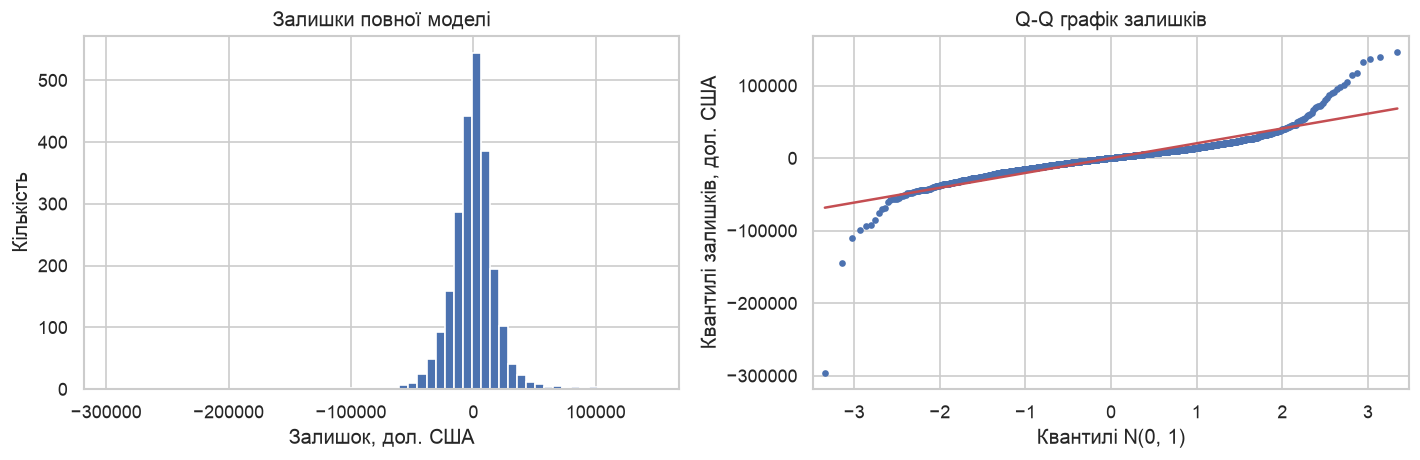

In [8]:
# Обчисліть conf_int() та виконайте обраний тест нормальності залишків.
# ========= YOUR CODE STARTS HERE ========= #

ci = full_model.conf_int(alpha=ALPHA).loc["LotArea"]
t_crit = stats.t.ppf(1 - ALPHA / 2, full_model.df_resid)
ci_manual = full_model.params["LotArea"] + np.array([-1, 1]) * t_crit * full_model.bse["LotArea"]
assert np.allclose(ci, ci_manual)
display(pd.Series({"beta_LotArea": full_model.params["LotArea"], "SE": full_model.bse["LotArea"],
                   "t_0.975,n-k": t_crit, "Нижня межа": ci.iloc[0], "Верхня межа": ci.iloc[1],
                   "p t-тесту": full_model.pvalues["LotArea"]}).to_frame("LotArea, повна модель"))

jb = stats.jarque_bera(full_model.resid)
display(pd.Series({"JB": jb.statistic, "p": jb.pvalue, "Асиметрія": stats.skew(full_model.resid),
                   "Ексцес (нормальний = 3)": stats.kurtosis(full_model.resid, fisher=False)})
        .to_frame("Jarque-Bera для залишків"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(full_model.resid, bins=60, edgecolor="white")
axes[0].set(title="Залишки повної моделі", xlabel="Залишок, дол. США", ylabel="Кількість")
sm.qqplot(full_model.resid, line="s", ax=axes[1], markersize=3)
axes[1].set(title="Q-Q графік залишків", xlabel="Квантилі N(0, 1)", ylabel="Квантилі залишків, дол. США")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "problem5_normality.png")
plt.show()


***Answer***

95% довірчий інтервал для $\beta_{LotArea}$ у повній моделі:
$$\widehat\beta\pm t_{0.975,\,n-k}\,SE(\widehat\beta)=0.7987\pm1.961\cdot0.1101=[0.583;\;1.015]\ \text{дол. за кв. фут}.$$

**Економічний зміст:** за інших рівних додаткові 1000 кв. футів ділянки пов'язані зі зростанням середньої ціни приблизно на 583–1015 дол. Число «95%» стосується процедури: якби ми багато разів брали нові вибірки й будували інтервал так само, близько 95% інтервалів накрили б справжнє $\beta$ (якщо припущення моделі виконуються). Це інтервал для коефіцієнта, а не для ціни окремого будинку.

**Зв'язок із тестом:** двосторонній t-тест $H_0:\beta=\beta_0$ на рівні $\alpha$ відхиляє $H_0$ тоді й лише тоді, коли $\beta_0$ не потрапляє в $(1-\alpha)$-інтервал. Для значущості беремо $\beta_0=0$. Тут 0 лежить поза $[0.583;\,1.015]$, тому `LotArea` значуща на рівні 0.05 ($p=5.7\cdot10^{-13}$). Інтервал дає більше, ніж p-значення: він показує ще й правдоподібний розмір ефекту.

**Нормальність залишків.** Тест Jarque–Bera: $JB=\frac n6\big(S^2+\frac{(K-3)^2}4\big)$, де $S$ — асиметрія, $K$ — ексцес; $H_0$ — нормальний розподіл. Отримали $JB=66038$, $p\approx0$ (менше за точність обчислень). Асиметрія $-0.60$, ексцес 28.6 (для нормального — 3): хвости дуже важкі. На Q–Q графіку крайні точки далеко від прямої, окремі залишки сягають $-300$ тис. дол. **Припущення нормальності не виконується.**

Отже, точні t-інтервали — лише наближення. Для $n=2414$ вони залишаються наближено правильними, якщо інші припущення (незалежність, однаковий розкид похибок) виконуються. Проте в пункті 8 видно, що розкид залишків зростає з ціною, а кілька продажів дуже впливові. Тому стандартні похибки й інтервали слід сприймати обережно.

## (7)

Більшість змінних можуть виявитися незначущими, тому нам слід знайти найменшу (найбільш економну) модель, яка все ще має хорошу пояснювальну здатність. Виберіть таку модель за допомогою покрокового відбору змінних (stepwise model selection), реалізувавши власний алгоритм на основі метрик AIC/BIC або скориставшись методами регуляризації Lasso з sklearn.linear_model. Детально поясніть, як цей метод/підхід працює у вашому коді. Працюйте з цією обраною моделлю на всіх наступних кроках.

In [9]:
# Реалізуйте обраний метод відбору; збережіть повну та обрану моделі.
# ========= YOUR CODE STARTS HERE ========= #

# Група = одна змінна: числова - один стовпець, категоріальна - усі її фіктивні.
groups = {column: [column] for column in numeric}
for column in categorical:
    columns = [name for name in X_full.columns if name.startswith(column + "_")]
    if columns:
        groups[column] = columns
assert sum(len(columns) for columns in groups.values()) == X_full.shape[1] - 1


def backward_bic(X, y, groups):
    """Зворотний відбір: щоразу вилучаємо групу, без якої BIC найменший."""
    active = list(groups)
    model = sm.OLS(y, X).fit()
    history = [{"Крок": 0, "Вилучено": "-", "k": len(model.params), "BIC": model.bic}]
    while True:
        best_group, best_model = None, None
        for group in active:
            columns = ["const"] + [c for g in active if g != group for c in groups[g]]
            candidate = sm.OLS(y, X[columns]).fit()
            if best_model is None or candidate.bic < best_model.bic:
                best_group, best_model = group, candidate
        if best_model.bic >= model.bic:  # жодне вилучення не зменшує BIC - зупинка
            return model, active, pd.DataFrame(history)
        active.remove(best_group)
        model = best_model
        history.append({"Крок": len(history), "Вилучено": best_group, "k": len(model.params), "BIC": model.bic})


selected_model, selected_terms, history = backward_bic(X_full, y, groups)
X_selected = X_full[selected_model.model.exog_names]
with pd.option_context("display.max_rows", 100):
    display(history)
print(f"Залишилось {len(selected_terms)} з {len(groups)} змінних:", selected_terms)
display(pd.DataFrame({
    "Змінних": [len(groups), len(selected_terms)],
    "Параметрів k": [len(full_model.params), len(selected_model.params)],
    "R²": [full_model.rsquared, selected_model.rsquared],
    "Скоригований R²": [full_model.rsquared_adj, selected_model.rsquared_adj],
    "AIC": [full_model.aic, selected_model.aic],
    "BIC": [full_model.bic, selected_model.bic],
}, index=["Повна", "Після відбору"]))


,Крок,Вилучено,k,BIC
0,0,-,269,56866.2
1,1,Exterior2nd,254,56759.9
2,2,MSSubClass,240,56685.2
3,3,Exterior1st,225,56613.5
4,4,SaleType,216,56553.1
5,5,HouseStyle,209,56511.5
6,6,MSZoning,203,56472.5
7,7,RoofStyle,198,56436.6
8,8,GarageType,192,56403
9,9,Foundation,187,56371.2


Залишилось 29 з 75 змінних: ['LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'BedroomAbvGr', 'KitchenAbvGr', 'Fireplaces', 'GarageArea', 'ScreenPorch', 'LandSlope', 'Neighborhood', 'Condition2', 'BldgType', 'RoofMatl', 'MasVnrType', 'ExterQual', 'BsmtQual', 'BsmtExposure', 'KitchenQual', 'PoolQC', 'MiscFeature', 'SaleCondition']


,Змінних,Параметрів k,R²,Скоригований R²,AIC,BIC
Повна,75,269,0.939889,0.932378,55308.9,56866.2
Після відбору,29,91,0.928386,0.925611,55375.6,55902.4


***Answer***

Використано власний **зворотний покроковий відбір за BIC**:
$$BIC=-2\ln\widehat L+k\ln n,\qquad -2\ln\widehat L=n\ln\frac{RSS}{n}+\text{const}.$$
Перший доданок вимірює якість підгонки, другий — штраф за кількість параметрів $k$. Для $n=2414$ штраф за параметр $\ln n\approx7.8$, у AIC — лише 2. Тому BIC обирає економніші моделі, а нам потрібна саме найменша модель із добрим поясненням.

Як працює `backward_bic`:
1. Починаємо з повної моделі (75 змінних, $k=269$, $BIC=56866.2$).
2. Для кожної змінної, яка ще є в моделі, оцінюємо модель без неї та рахуємо BIC.
3. Вилучаємо змінну, без якої BIC найменший, — але лише якщо він менший за поточний.
4. Повторюємо, доки жодне вилучення не зменшує BIC.

Категоріальна змінна вилучається **цілком** (усі її фіктивні разом), як у F-тесті з пункту 4. Інакше результат залежав би від вибору базової категорії. Константа лишається завжди. Усі моделі оцінюються на тих самих 2414 рядках, тому їхні BIC можна порівнювати.

**Результат:** за 46 кроків вилучено 46 змінних, залишилося **29 змінних ($k=91$)**. Першими пішли змінні з багатьма рівнями, але малим новим внеском: `Exterior2nd`, `MSSubClass`, `Exterior1st`, `SaleType`. Залишилися, зокрема, площі (`LotArea`, `1stFlrSF`, `2ndFlrSF`, площі підвалу, `GarageArea`), якість (`OverallQual`, `ExterQual`, `KitchenQual`, `BsmtQual`), роки (`YearBuilt`, `YearRemodAdd`) і `Neighborhood`.

| | Змінних | $k$ | $R^2$ | Скоригований $R^2$ | AIC | BIC |
|---|---|---|---|---|---|---|
| Повна | 75 | 269 | 0.9399 | 0.9324 | 55308.9 | 56866.2 |
| Після відбору | 29 | 91 | 0.9284 | 0.9256 | 55375.6 | 55902.4 |

Утричі менша модель втрачає лише 0.012 у $R^2$, а BIC зменшився на 964. AIC повної моделі менший — AIC штрафує слабше й обрав би більшу модель.

Зауваження:
- `MSSubClass` був спільно значущим за F-тестом ($p=0.006$), але BIC його вилучив: зменшення штрафу $14\ln n\approx109$ більше за погіршення підгонки. Значущість на рівні 0.05 і відбір за BIC — різні критерії.
- Покроковий відбір перевіряє не всі можливі моделі, тому не гарантує найкращої з них.
- Серед залишених є змінні з дуже рідкісними рівнями (`RoofMatl`, `PoolQC`, `MiscFeature`, `Condition2`). Пункт 8 показує, що вони точно підганяють окремі продажі.

## (8)

Іноді дані містять викиди (outliers), що спричиняє зсув в оцінках параметрів. Перевірте наявність викидів за допомогою графіків залишків, відстані Кука (Cook's distance) та важеля (leverage). Для обчислення цих показників скористайтеся класом OLSInfluence з бібліотеки statsmodels. Зверніть прискіпливу увагу на спостереження з найбільшим значенням важеля (leverage). Що саме робить це спостереження таким видатним (ви можете побудувати sns.boxplot для інтервальних змінних або порахувати частоти через value_counts())?

k = 91, n = 2414, середній важіль k/n = 0.0377, орієнтир 2k/n = 0.0754
Спостережень з h > 2k/n: 160 | з h = 1: 8


,Order,SalePrice,h,Залишок,Рідкісні рівні (кількість продажів)
0,211,107500,1,1.9354e-09,KitchenQual=Po (1)
1,1402,241500,1,-6.51926e-09,RoofMatl=Membran (1)
2,1499,160000,1,-3.59141e-08,RoofMatl=ClyTile (1)
3,1908,137000,1,-1.05938e-08,RoofMatl=Roll (1)
4,2181,183850,1,-2.11294e-08,MiscFeature=Elev (1)
5,2299,80000,1,-9.19681e-09,MasVnrType=CBlock (1)
6,2351,250000,1,-1.1205e-08,"PoolQC=Fa (2), MiscFeature=TenC (1)"
7,2358,181000,1,-5.52973e-09,PoolQC=Fa (2)


RoofMatl.value_counts(): {'CompShg': 2384, 'Tar&Grv': 15, 'WdShngl': 7, 'WdShake': 5, 'Membran': 1, 'ClyTile': 1, 'Roll': 1}


,Order,Neighborhood,SaleCondition,1stFlrSF,SalePrice,Прогноз,Залишок,h,Cook_D
2181,2182,Edwards,Partial,3138,184750,488917,-304167,0.2948,1.1646
513,514,Somerst,Normal,2490,468000,325649,142351,0.269147,0.216821
1760,1761,NoRidge,Abnorml,2411,745000,623316,121684,0.290943,0.181955
2570,2571,NAmes,Abnorml,1360,235000,346477,-111477,0.280608,0.143083
1014,1015,StoneBr,Normal,1710,334000,239232,94768,0.281999,0.104321


,Order,Neighborhood,SaleCondition,LotArea,1stFlrSF,2ndFlrSF,YearBuilt,SalePrice,h,Cook_D
2180,2181,Edwards,Partial,39290,5095,0,2008,183850,1,NaN
1498,1499,Edwards,Partial,63887,4692,950,2008,160000,1,NaN
2181,2182,Edwards,Partial,40094,3138,1538,2007,184750,0.2948,1.1646
956,957,Timber,Normal,215245,2036,0,1965,375000,0.663288,0.00925675
Медіана вибірки,NaN,NaN,NaN,9245.5,1073,0,1972,157000,NaN,NaN


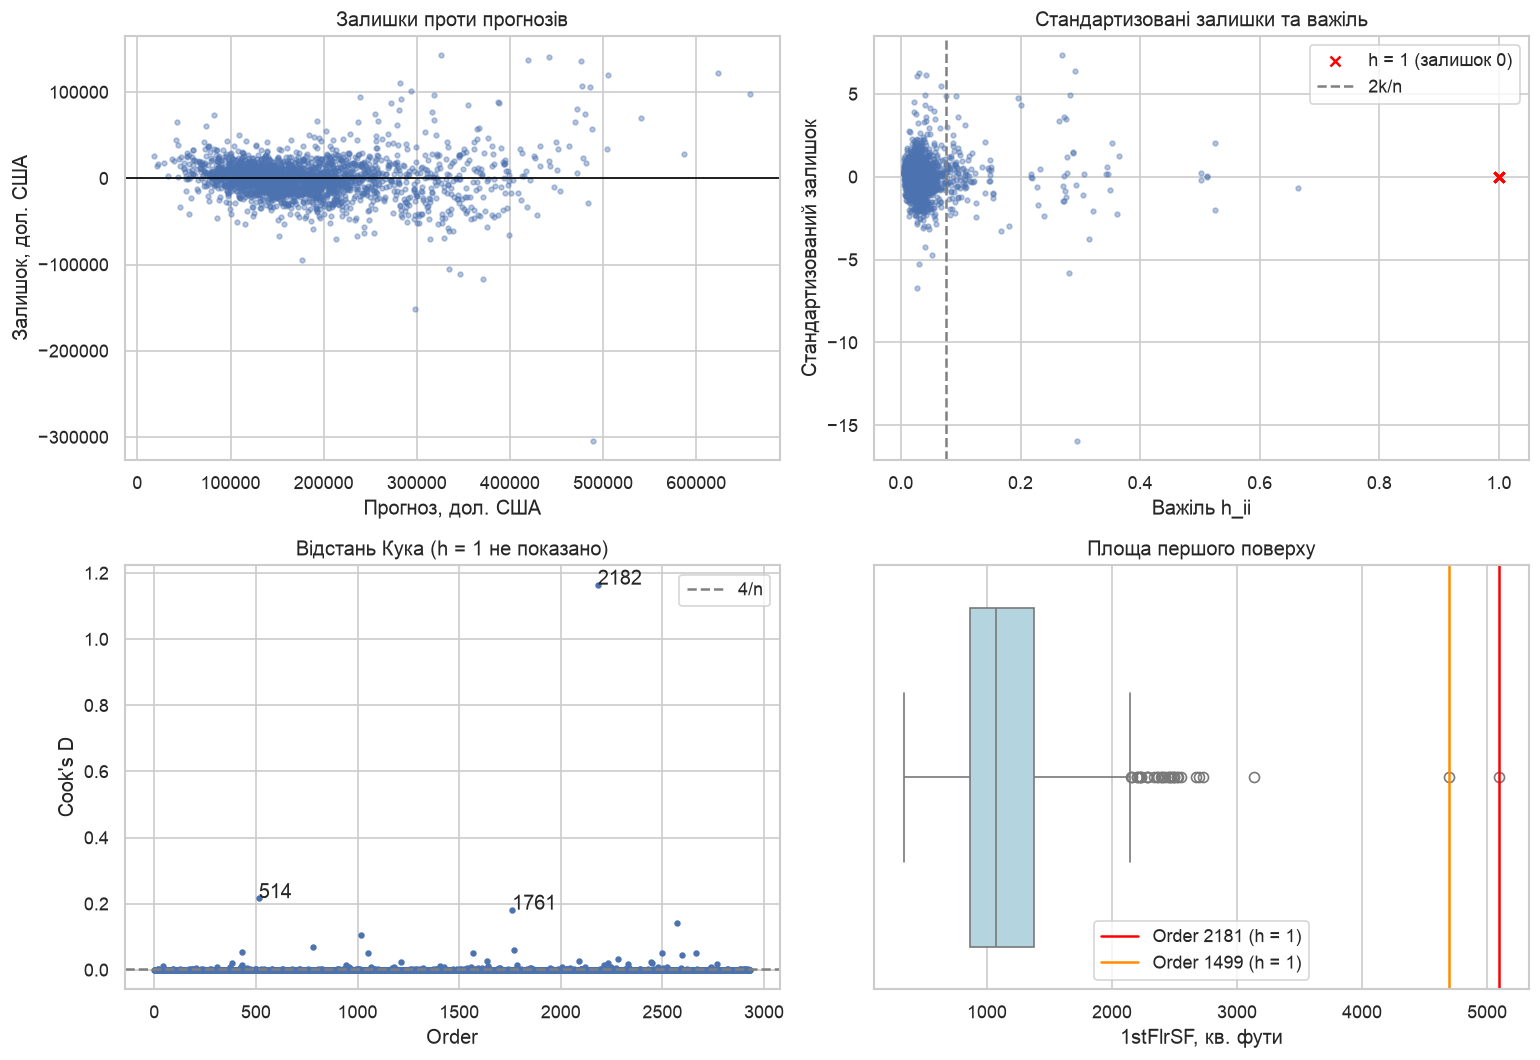

,Усі продажі,Без Order 2182
LotArea,0.789743,0.91746
1stFlrSF,50.8064,54.2288
2ndFlrSF,57.7844,62.483
BsmtFinSF1,42.3016,44.3385
OverallQual,7000.48,6993.69
BedroomAbvGr,-4154.21,-5282.09


In [10]:
# Використайте OLSInfluence для обраної моделі та побудуйте діагностику.
# ========= YOUR CODE STARTS HERE ========= #

influence = OLSInfluence(selected_model)
with np.errstate(invalid="ignore", divide="ignore"):  # для h = 1 формули містять 0/0
    leverage = pd.Series(influence.hat_matrix_diag, index=y.index)
    student = pd.Series(influence.resid_studentized_internal, index=y.index)
    cooks = pd.Series(influence.cooks_distance[0], index=y.index)
n, k = X_selected.shape
assert np.isclose(leverage.sum(), k)  # сума важелів = кількість параметрів
exact_fit = leverage > 1 - 1e-8
cooks[exact_fit] = np.nan    # h = 1: залишок 0, D = 0/0 не визначено
student[exact_fit] = np.nan
print(f"k = {k}, n = {n}, середній важіль k/n = {k / n:.4f}, орієнтир 2k/n = {2 * k / n:.4f}")
print("Спостережень з h > 2k/n:", (leverage > 2 * k / n).sum(), "| з h = 1:", exact_fit.sum())

# Для h = 1 шукаємо рідкісні рівні (<= 2 продажі) обраних категоріальних змінних.
selected_categorical = [g for g in selected_terms if g in categorical]
rows = []
for index in leverage.index[exact_fit]:
    rare = [f"{g}={analysis.at[index, g]} ({(analysis[g] == analysis.at[index, g]).sum()})"
            for g in selected_categorical if (analysis[g] == analysis.at[index, g]).sum() <= 2]
    rows.append({"Order": analysis.at[index, "Order"], "SalePrice": y[index], "h": leverage[index],
                 "Залишок": selected_model.resid[index], "Рідкісні рівні (кількість продажів)": ", ".join(rare)})
display(pd.DataFrame(rows))
print("RoofMatl.value_counts():", analysis["RoofMatl"].value_counts().to_dict())

diagnostics = analysis[["Order", "Neighborhood", "SaleCondition", "1stFlrSF", "SalePrice"]].assign(
    Прогноз=selected_model.fittedvalues, Залишок=selected_model.resid, h=leverage, Cook_D=cooks)
display(diagnostics.nlargest(5, "Cook_D"))

# Два найбільші будинки серед h = 1, найбільший Cook's D та найбільший важіль серед h < 1.
largest_exact = analysis.loc[exact_fit, "1stFlrSF"].nlargest(2).index
notable = list(largest_exact) + [cooks.idxmax(), leverage[~exact_fit].idxmax()]
show = ["LotArea", "1stFlrSF", "2ndFlrSF", "YearBuilt", "SalePrice"]
display(pd.concat([
    analysis.loc[notable, ["Order", "Neighborhood", "SaleCondition"] + show].assign(h=leverage[notable], Cook_D=cooks[notable]),
    analysis[show].median().to_frame("Медіана вибірки").T]))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].scatter(selected_model.fittedvalues, selected_model.resid, s=8, alpha=0.4)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set(title="Залишки проти прогнозів", xlabel="Прогноз, дол. США", ylabel="Залишок, дол. США")
axes[0, 1].scatter(leverage, student, s=8, alpha=0.4)
axes[0, 1].scatter(leverage[exact_fit], np.zeros(exact_fit.sum()), color="red", marker="x", label="h = 1 (залишок 0)")
axes[0, 1].axvline(2 * k / n, color="gray", linestyle="--", label="2k/n")
axes[0, 1].set(title="Стандартизовані залишки та важіль", xlabel="Важіль h_ii", ylabel="Стандартизований залишок")
axes[0, 1].legend()
axes[1, 0].scatter(analysis["Order"], cooks, s=8)
axes[1, 0].axhline(4 / n, color="gray", linestyle="--", label="4/n")
for index in cooks.nlargest(3).index:
    axes[1, 0].annotate(str(analysis.at[index, "Order"]), (analysis.at[index, "Order"], cooks[index]))
axes[1, 0].set(title="Відстань Кука (h = 1 не показано)", xlabel="Order", ylabel="Cook's D")
axes[1, 0].legend()
sns.boxplot(x=analysis["1stFlrSF"], ax=axes[1, 1], color="lightblue")
for index, color in zip(largest_exact, ["red", "darkorange"]):
    axes[1, 1].axvline(analysis.at[index, "1stFlrSF"], color=color, label=f"Order {analysis.at[index, 'Order']} (h = 1)")
axes[1, 1].set(title="Площа першого поверху", xlabel="1stFlrSF, кв. фути")
axes[1, 1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "problem5_influence.png")
plt.show()

# Чутливість: оцінки без спостереження з найбільшим Cook's D.
top_cook = cooks.idxmax()
without_top = sm.OLS(y.drop(top_cook), X_selected.drop(top_cook)).fit()
check_terms = ["LotArea", "1stFlrSF", "2ndFlrSF", "BsmtFinSF1", "OverallQual", "BedroomAbvGr"]
display(pd.DataFrame({"Усі продажі": selected_model.params[check_terms],
                      f"Без Order {analysis.at[top_cook, 'Order']}": without_top.params[check_terms]}))


***Answer***

**Важіль** $h_{ii}$ — діагональ матриці $H=X(X^TX)^{-1}X^T$. Він залежить лише від регресорів: наскільки незвичний набір значень $x_i$. Маємо $0\le h_{ii}\le1$ і $\sum_i h_{ii}=k=91$, тобто середній важіль $k/n=0.038$. Орієнтир для великого важеля — $2k/n=0.075$; його перевищують 160 продажів.

**Відстань Кука** поєднує залишок і важіль:
$$D_i=\frac{e_i^2}{k\,s^2}\cdot\frac{h_{ii}}{(1-h_{ii})^2}.$$
Вона показує, наскільки змінилися б усі прогнози, якби вилучити $i$-те спостереження. Орієнтир — $4/n$; $D_i>1$ означає дуже впливове спостереження.

**Найбільший важіль: $h=1$ у 8 продажів.** Кожен із них має рівень категоріальної змінної, якого немає в інших продажах (таблиця та `value_counts()`): `RoofMatl` = ClyTile, Membran, Roll — по одному будинку; `KitchenQual` = Po, `MasVnrType` = CBlock, `MiscFeature` = Elev, TenC — теж по одному. `PoolQC` = Fa має два продажі, але один із них уже «закритий» індикатором TenC. Фіктивна змінна такого рівня дорівнює 1 лише в одному рядку. Тому її коефіцієнт підбирається так, щоб прогноз збігся з ціною: залишок 0, $h=1$. Тоді $D_i=0/0$ не визначена, тож відстань Кука **не помічає** такі точки, хоча модель вивчила їх «напам'ять».

Найбільш показові — **Order 1499 і 2181**. Це нові (2008 р.) величезні будинки в районі Edwards: площа першого поверху 4692 і 5095 кв. футів при медіані 1073 (boxplot). Їх продано з позначкою `Partial` (будинок не був завершений на момент оцінки) лише за 160 і 184 тис. дол. Order 1499 — єдиний із черепичним дахом (ClyTile), Order 2181 — єдиний із ліфтом (Elev). Рідкісні індикатори «маскують» ці два найбільші викиди. Саме тому BIC залишив `RoofMatl` і `MiscFeature`. У пункті 11 без цих індикаторів їхні помилки прогнозу сягають 545–656 тис. дол.

Серед $h<1$ найбільший важіль має **Order 957** ($h=0.663$): найбільша ділянка (215245 кв. футів, у 23 рази більше медіани). Проте модель прогнозує його ціну добре (залишок $-8.6$ тис.), тому $D=0.009$. Великий важіль ще не означає великого впливу.

**Найбільша відстань Кука — Order 2182** ($D=1.16$, $h=0.29$): ще один новий великий будинок `Partial` в Edwards. Ціна 184750 дол. при прогнозі 488917, залишок $-304$ тис. Він сильно тягне оцінки до себе: без нього коефіцієнт `LotArea` змінюється з 0.79 на 0.92, `BedroomAbvGr` — з $-4154$ на $-5282$. Наступні за впливом — Order 514 і 1761 ($D\approx0.2$).

Графік «залишки проти прогнозів» має форму лійки: розкид зростає з прогнозом. Це гетероскедастичність, ще один аргумент за $\log(SalePrice)$.

Висновок: викиди є, і найнебезпечніші з них — нетипові часткові продажі дуже великих будинків. Ми не вилучаємо їх автоматично, але висновки чутливі до них. Можливі покращення — об'єднати рідкісні рівні в «інше» або окремо дослідити продажі `Partial` великих будинків.

## (9)

Часто в даних трапляються пропуски. Виберіть 5 випадкових рядків у наборі даних і видаліть значення для LotArea. Реалізуйте щонайменше два підходи для заповнення (імпутації) цих значень за допомогою інструментів pandas або класу SimpleImputer / IterativeImputer з sklearn.impute. Запишіть відповідні формули/модель та наведіть мотивацію для вашого підходу. Зауважте, що для імпутації слід використовувати повний набір даних, а не лише набір змінних після відбору ознак. Зверніть увагу: ваш алгоритм має обробляти лише дійсні пропуски (як-от у LotFrontage або ваші штучні пропуски в LotArea), а не структурні категорії NA, які ви мали зберегти як окремі факторні рівні.

In [11]:
# Працюйте з копією повного набору; збережіть початкові значення п’яти рядків.
# ========= YOUR CODE STARTS HERE ========= #

# Повний df: усі 2930 рядків і всі колонки. Ховаємо LotArea у 5 випадкових рядках.
masked_index = rng.choice(df.index.to_numpy(), size=5, replace=False)
true_lotarea = df.loc[masked_index, "LotArea"]
df_missing = df.copy()
df_missing["LotArea"] = df_missing["LotArea"].astype(float)
df_missing.loc[masked_index, "LotArea"] = np.nan

# Заповнюємо лише числові NaN. Категоріальні "NA" не чіпаємо; GarageYrBlt без гаража
# не є пропуском; MSSubClass - коди категорій; SalePrice - відгук, який пояснюємо.
impute_columns = [c for c in df.select_dtypes("number").columns
                  if c not in ["Order", "PID", "SalePrice", "MSSubClass", "GarageYrBlt"]]
print(f"Колонок для імпутації: {len(impute_columns)}; пропуски:",
      df_missing[impute_columns].isna().sum()[lambda s: s > 0].to_dict())

median_filled = df_missing.copy()
median_filled[impute_columns] = SimpleImputer(strategy="median").fit_transform(df_missing[impute_columns])
iterative_filled = df_missing.copy()
iterative_filled[impute_columns] = IterativeImputer(max_iter=25, random_state=SEED).fit_transform(df_missing[impute_columns])

imputation = pd.DataFrame({
    "Order": df.loc[masked_index, "Order"], "Neighborhood": df.loc[masked_index, "Neighborhood"],
    "Справжня LotArea": true_lotarea,
    "Медіана": median_filled.loc[masked_index, "LotArea"],
    "IterativeImputer": iterative_filled.loc[masked_index, "LotArea"],
})
display(imputation)
display(pd.DataFrame({name: {"MAE, кв. фути": (imputation[name] - true_lotarea).abs().mean(),
                             "Медіана |помилки|, кв. фути": (imputation[name] - true_lotarea).abs().median()}
                      for name in ["Медіана", "IterativeImputer"]}).T)

# Перевірки: заповнено лише справжні пропуски; решту даних не змінено.
for filled in (median_filled, iterative_filled):
    assert filled[impute_columns].notna().all().all()
    assert filled["GarageYrBlt"].isna().sum() == df["GarageYrBlt"].isna().sum()
    pd.testing.assert_frame_equal(filled[categorical], df[categorical])
    observed = df_missing[impute_columns].notna().to_numpy()
    assert np.allclose(filled[impute_columns].to_numpy()[observed], df_missing[impute_columns].to_numpy()[observed])
print("LotFrontage: медіана =", median_filled["LotFrontage"][df["LotFrontage"].isna()].iloc[0],
      "| IterativeImputer, діапазон заповнених:",
      iterative_filled["LotFrontage"][df["LotFrontage"].isna()].agg(["min", "median", "max"]).round(1).to_dict())


Колонок для імпутації: 34; пропуски: {'LotFrontage': 490, 'LotArea': 5, 'MasVnrArea': 23, 'BsmtFinSF1': 1, 'BsmtFinSF2': 1, 'BsmtUnfSF': 1, 'TotalBsmtSF': 1, 'BsmtFullBath': 2, 'BsmtHalfBath': 2, 'GarageCars': 1, 'GarageArea': 1}


,Order,Neighborhood,Справжня LotArea,Медіана,IterativeImputer
2265,2266,Timber,13758,9434,6488.77
1285,1286,OldTown,10440,9434,8673.19
1916,1917,NAmes,8760,9434,9665.54
261,262,CollgCr,10650,9434,12519.2
1268,1269,NAmes,7200,9434,7612.11


,"MAE, кв. фути","Медіана |помилки|, кв. фути"
Медіана,1890.8,1216
IterativeImputer,2444.58,1766.81


LotFrontage: медіана = 68.0 | IterativeImputer, діапазон заповнених: {'min': 44.7, 'median': 70.6, 'max': 258.7}


***Answer***

Пропуски створено в копії **повного** `df` (2930 рядків, усі колонки). П'ять випадкових рядків вибрано через `rng` із `SEED = 42`: Order 2266, 1286, 1917, 262, 1269. Справжні значення збережено лише для перевірки.

**Що вважаємо пропуском:** лише `NaN` у числових колонках. Це справжні пропуски `LotFrontage` (490), `MasVnrArea` (23), кілька пропусків у колонках підвалу й гаража та наші 5 штучних у `LotArea`. Не чіпаємо:
- категоріальні `"NA"` (немає алеї, басейну, підвалу…). Це окремі рівні, а не пропуски; `keep_default_na=False` зберіг їх як текст (перевірено `assert`);
- `GarageYrBlt` будинків без гаража: такого року не існує;
- `SalePrice` (відгук, який потім пояснюємо) і `MSSubClass` (коди категорій).

Імпутація використовує 34 числові колонки.

**Підхід 1 — медіана** (`SimpleImputer(strategy="median")`):
$$\widehat x_i=\operatorname{median}\{x_j:\ x_j\ \text{спостережено}\}.$$
Для `LotArea` це 9434 кв. фути, для `LotFrontage` — 68 футів. Медіана проста й не залежить від кількох гігантських ділянок, які сильно змістили б середнє. Але всі пропуски отримують одне значення, а інші ознаки будинку ігноруються.

**Підхід 2 — `IterativeImputer`:** кожну колонку з пропусками по черзі прогнозуємо лінійною регресією на всі інші колонки:
$$\widehat x_{i,LotArea}=b_0+\sum_j b_j x_{ij}.$$
Спочатку пропуски заповнюються середніми, далі значення уточнюються раунд за раундом (до 25 раундів), доки зміни не стануть малими. Модель за замовчуванням — `BayesianRidge`, лінійна регресія з невеликим штрафом на коефіцієнти. Мотивація: площа ділянки пов'язана з фасадом, площею будинку, гаражем тощо. Тому імпутацію робимо на **повному** наборі, а не лише на 29 змінних після відбору: інші змінні містять інформацію про пропущене значення.

**Результат на 5 прихованих значеннях:** середня абсолютна помилка (MAE) медіани — 1891 кв. фут, `IterativeImputer` — 2445. Тут проста медіана виявилася точнішою; регресійний метод найбільше помилився для Order 2266 (13758 → 6489). П'яти значень замало для загального висновку. Можлива причина: лінійна модель на сирій шкалі погано описує скошену `LotArea`; варто було б імпутувати $\log(LotArea)$.

Обидва методи дають одне «найкраще» значення й не показують невизначеності пропуску; медіана ще й зменшує розкид змінної. Регресії в пунктах 10–11 продовжуємо на тих самих 2414 повних спостереженнях, щоб моделі порівнювалися на однакових даних.

## (10)

Тепер розглянемо модель із SalePrice та модель із log(SalePrice). Запустіть відповідний тест (наприклад, тест Девідсона-Маккіннона або порівняння через трансформовані залишки), щоб вирішити, яка з моделей є кращою. Поясніть ідею цього тесту і чому ви не можете прийняти аналогічне рішення за допомогою простого порівняння критеріїв AIC/BIC, виданих statsmodels для цих двох моделей напряму.

In [12]:
# Підготуйте дві специфікації й реалізуйте відповідний тест порівняння.
# ========= YOUR CODE STARTS HERE ========= #

level_model = selected_model                      # SalePrice ~ X_selected
log_model = sm.OLS(np.log(y), X_selected).fit()   # log(SalePrice) ~ X_selected

# Ділимо ціну на середнє геометричне: тоді RSS двох моделей мають одну шкалу.
geometric_mean = np.exp(np.log(y).mean())
y_scaled = y / geometric_mean
rss_level = sm.OLS(y_scaled, X_selected).fit().ssr
rss_log = sm.OLS(np.log(y_scaled), X_selected).fit().ssr
n_obs = len(y)
chi2_stat = n_obs / 2 * np.log(max(rss_level, rss_log) / min(rss_level, rss_log))
chi2_p = stats.chi2.sf(chi2_stat, df=1)
display(pd.Series({"Середнє геометричне ціни, дол.": geometric_mean, "RSS лінійної (y / GM)": rss_level,
                   "RSS лог-лінійної (log(y / GM))": rss_log, "chi2 = n/2 * ln(RSS_max / RSS_min)": chi2_stat,
                   "p, chi2(1)": chi2_p, "chi2_0.95(1)": stats.chi2.ppf(1 - ALPHA, 1)}).to_frame("Порівняння"))

# AIC зі statsmodels та виправлений AIC лог-моделі для щільності самої ціни.
jacobian = np.log(y).sum()
aic_table = pd.Series({"AIC лінійної моделі": level_model.aic, "AIC лог-моделі (для log y)": log_model.aic,
                       "AIC лог-моделі для y = AIC + 2*sum(log y)": log_model.aic + 2 * jacobian})
display(aic_table.to_frame("AIC"))
assert np.isclose(abs(level_model.llf - (log_model.llf - jacobian)), chi2_stat)


,Порівняння
"Середнє геометричне ціни, дол.",163943
RSS лінійної (y / GM),44.7272
RSS лог-лінійної (log(y / GM)),34.5668
chi2 = n/2 * ln(RSS_max / RSS_min),311.029
"p, chi2(1)",1.30349e-69
chi2_0.95(1),3.84146


,AIC
AIC лінійної моделі,55375.6
AIC лог-моделі (для log y),-3217.56
AIC лог-моделі для y = AIC + 2*sum(log y),54753.5


***Answer***

Порівнюємо дві моделі з тими самими 29 змінними після відбору:
$$(A)\ SalePrice=X\beta+\varepsilon,\qquad (B)\ \log SalePrice=X\gamma+u.$$

**Чому не можна просто порівняти AIC/BIC зі statsmodels.** Вони обчислені для **різних залежних змінних**: $AIC_A=55375.6$ описує щільність ціни, $AIC_B=-3217.6$ — щільність логарифма ціни. Модель B не стає «кращою» через від'ємне число: змінилася лише шкала. Щоб перейти від щільності $\log y$ до щільності $y$, треба врахувати якобіан заміни: $f_Y(y)=f_{\log Y}(\log y)\cdot\frac1y$, тобто $\ln L_y=\ln L_{\log y}-\sum_i\log y_i$. Тоді
$$AIC_B^{(y)}=-3217.6+2\sum_i\log y_i=54753.5.$$
Так само RSS і $R^2$ двох моделей мають різні одиниці: дол.² і квадрати логарифмічних одиниць.

**Тест через трансформовані залишки (Box–Cox, Zarembka).** Ділимо ціну на середнє геометричне $GM=\exp\big(\frac1n\sum\log y_i\big)=163943$ дол.: $\tilde y=y/GM$. Тоді $\sum_i\log\tilde y_i=0$, якобіан зникає, і RSS обох моделей можна порівнювати напряму:
$$RSS_A(\tilde y)=44.73,\qquad RSS_B(\log\tilde y)=34.57.$$
Менший RSS означає кращу модель. Чи значуща різниця:
$$\chi^2=\frac n2\ln\frac{RSS_{max}}{RSS_{min}}=\frac{2414}{2}\ln\frac{44.73}{34.57}=311.0,$$
за $H_0$ «обидві моделі однаково добре описують дані» статистика має приблизно розподіл $\chi^2(1)$. $311.0>3.84$, $p\approx1.3\cdot10^{-69}$, тому **лог-лінійна модель значно краща**. Це збігається з виправленим AIC ($54753.5<55375.6$). По суті, це той самий розрахунок: $\chi^2$ дорівнює модулю різниці виправлених логарифмів правдоподібності (перевірено `assert`).

Результат узгоджується з графіками: ціни скошені праворуч, а розкид залишків зростає з ціною (пункти 2, 8). Логарифм стискає великі ціни й робить розкид рівномірнішим.

Обмеження: розподіл $\chi^2(1)$ — наближення, яке спирається на нормальні похибки. Залишки мають важкі хвости, тому p-значення не варто сприймати буквально. Проте різниця велика: RSS лог-моделі на 23% менший.

## (11)

Ми хочемо оцінити прогнозну здатність побудованої регресії. Розглянемо повну модель та модель після відбору ознак. Порівняйте ці дві моделі за допомогою крос-валідації «залишення по одному» (LeaveOneOut) та 5-блочної крос-валідації (KFold) з бібліотеки sklearn.model_selection. Поясніть ідею цієї техніки за допомогою формул та зробіть висновок про прогностичну здатність обох моделей на основі метрики MSE.

,Схема,Модель,Параметрів,"MSE навчальне, дол.²","MSE крос-валідації, дол.²","RMSE, дол."
0,LeaveOneOut,Повна,269,4.18001e+08,9.55734e+08,30915
1,LeaveOneOut,Після відбору,91,4.97988e+08,9.20088e+08,30332.9
2,KFold (5 блоків),Повна,269,4.18001e+08,9.55302e+08,30908
3,KFold (5 блоків),Після відбору,91,4.97988e+08,9.19003e+08,30315.1


,Повна,Після відбору,Order
1498,-660415,-655580,1499
2180,-549931,-544663,2181
2181,-439550,-431320,2182
513,199807,194773,514
1760,154980,171614,1761


MSE LOO без трьох найбільших помилок (Order [1499, 2181, 2182] ): {'Повна': '5.705e+08', 'Після відбору': '5.428e+08'}


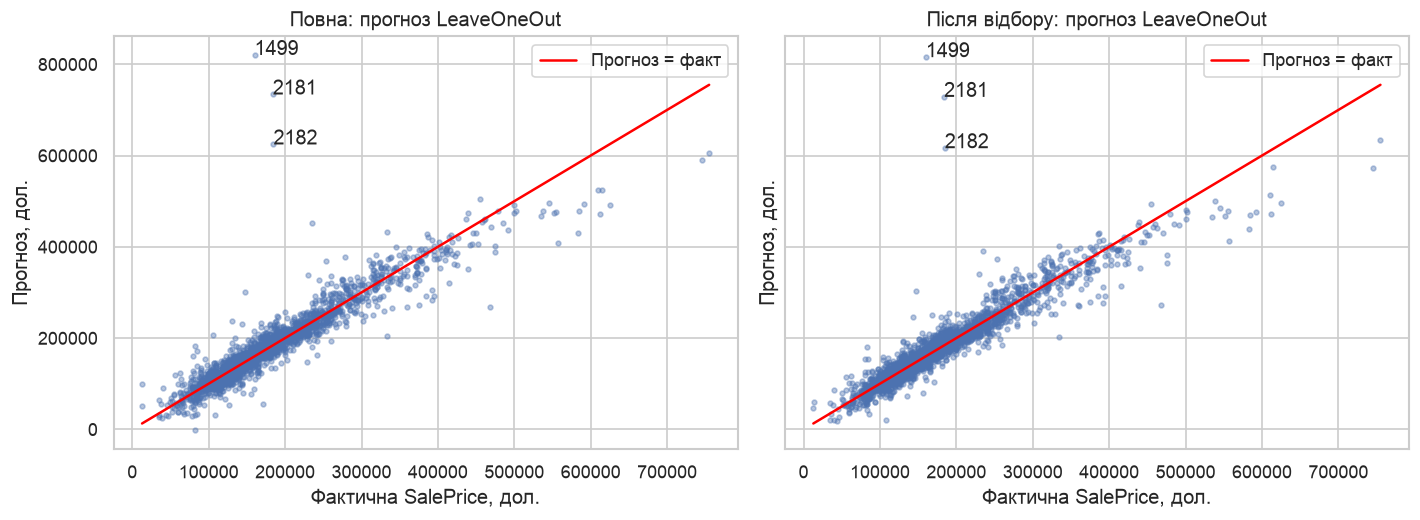

In [13]:
# Порівняйте повну й відібрану моделі через LeaveOneOut та KFold.
# ========= YOUR CODE STARTS HERE ========= #

X_full_cv = X_full.drop(columns="const")        # LinearRegression сама додає константу
X_selected_cv = X_selected.drop(columns="const")
assert np.allclose(LinearRegression().fit(X_selected_cv, y).predict(X_selected_cv), selected_model.fittedvalues)

splitters = {"LeaveOneOut": LeaveOneOut(),
             "KFold (5 блоків)": KFold(n_splits=5, shuffle=True, random_state=SEED)}
models = {"Повна": (X_full_cv, full_model), "Після відбору": (X_selected_cv, selected_model)}
cv_rows, cv_errors = [], {}
for scheme, splitter in splitters.items():
    for name, (X_cv, fitted_model) in models.items():
        prediction = cross_val_predict(LinearRegression(), X_cv, y, cv=splitter, n_jobs=-1)
        cv_errors[(scheme, name)] = y - prediction
        mse = np.mean((y - prediction) ** 2)
        cv_rows.append({"Схема": scheme, "Модель": name, "Параметрів": X_cv.shape[1] + 1,
                        "MSE навчальне, дол.²": fitted_model.ssr / n_obs,
                        "MSE крос-валідації, дол.²": mse, "RMSE, дол.": np.sqrt(mse)})
cv_results = pd.DataFrame(cv_rows)
display(cv_results)

loo_errors = pd.DataFrame({name: cv_errors[("LeaveOneOut", name)] for name in models})
loo_errors["Order"] = analysis["Order"]
display(loo_errors.reindex(loo_errors["Після відбору"].abs().sort_values(ascending=False).index).head(5))
worst = loo_errors["Після відбору"].abs().nlargest(3).index
print("MSE LOO без трьох найбільших помилок (Order", list(analysis.loc[worst, "Order"]), "):",
      {name: f"{np.mean(loo_errors.drop(worst)[name] ** 2):.4g}" for name in models})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    prediction = y - cv_errors[("LeaveOneOut", name)]
    ax.scatter(y, prediction, s=8, alpha=0.4)
    for index in worst:
        ax.annotate(str(analysis.at[index, "Order"]), (y[index], prediction[index]))
    ax.plot([y.min(), y.max()], [y.min(), y.max()], color="red", label="Прогноз = факт")
    ax.set(title=f"{name}: прогноз LeaveOneOut", xlabel="Фактична SalePrice, дол.", ylabel="Прогноз, дол.")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "problem5_cv.png")
plt.show()


***Answer***

**Ідея крос-валідації:** якість прогнозу оцінюємо на даних, яких модель не бачила під час навчання. Навчальна MSE оптимістична, бо модель частково підганяє шум конкретної вибірки.

**LeaveOneOut:** для кожного $i$ навчаємо модель на $n-1$ рядках без $i$-го й прогнозуємо $\widehat y_i^{(-i)}$:
$$MSE_{LOO}=\frac1n\sum_{i=1}^n\big(y_i-\widehat y_i^{(-i)}\big)^2\qquad(2414\ \text{підгонки}).$$

**KFold (5 блоків):** випадково (`SEED = 42`) ділимо рядки на блоки $V_1,\dots,V_5$. Кожен блок один раз є тестовим, а модель навчається на інших чотирьох:
$$MSE_{5}=\frac1n\sum_{v=1}^5\sum_{i\in V_v}\big(y_i-\widehat y_i^{(-V_v)}\big)^2.$$

Порівнюємо дві фіксовані моделі: повну (пункт 4) і обрану (пункт 7). `LinearRegression` дає ті самі коефіцієнти, що й OLS у statsmodels (перевірено `assert`).

| Модель | $k$ | MSE навчальна | MSE LOO | MSE 5-fold | RMSE LOO, дол. |
|---|---|---|---|---|---|
| Повна | 269 | $4.18\cdot10^8$ | $9.557\cdot10^8$ | $9.553\cdot10^8$ | 30915 |
| Після відбору | 91 | $4.98\cdot10^8$ | $9.201\cdot10^8$ | $9.190\cdot10^8$ | 30333 |

**Висновок:**
- На навчальних даних повна модель «краща» ($4.18\cdot10^8<4.98\cdot10^8$). Так буде завжди: більше параметрів — менший RSS.
- У крос-валідації — навпаки: **обрана модель має меншу MSE** за обома схемами (на 3.7% для LOO і на 3.8% для KFold). Зайві 178 параметрів повної моделі підганяли шум і трохи погіршили прогноз. Отже, обрана модель не лише простіша, а й прогнозує трохи краще.
- LOO і 5-блокова схема дали майже однакові оцінки, але KFold потребує 5 підгонок замість 2414.
- MSE поза навчальною вибіркою приблизно вдвічі більша за навчальну. Головний внесок дають три продажі — Order 1499, 2181, 2182 (помилки 430–660 тис. дол.). Без них $MSE_{LOO}$ дорівнює $5.71\cdot10^8$ для повної і $5.43\cdot10^8$ для обраної моделі — обрана все одно краща.
- Для продажу з унікальним рівнем категорії ($h=1$) у навчальній частині такого рівня немає. Його коефіцієнт не оцінюється: `LinearRegression` ставить 0, тобто прогнозує як для найчастішої категорії. Саме тому Order 1499 і 2181 отримують величезні помилки.
- Застереження: змінні відібрано за BIC на всіх 2414 рядках, а не окремо в кожному розбитті. Тому оцінка обраної моделі може бути трохи оптимістичною.